In [11]:
import numpy as np
import pandas as pd
import geopandas as gpd
from pathlib import Path

PROCESSED = Path("../data/processed")
b = gpd.read_parquet(PROCESSED / "barrios_variables.parquet")
print(b.shape)
print([c for c in b.columns if c.startswith(("dens_", "dist_"))])

(131, 71)
['dens_bares_cafeterias', 'dens_bibliotecas', 'dens_campos_futbol', 'dens_centros_comerciales', 'dens_centros_salud', 'dens_cines_teatros', 'dens_colegios', 'dens_coworkings', 'dens_discotecas', 'dens_estaciones_bicimad', 'dens_estaciones_cercanias', 'dens_estaciones_metro', 'dens_estaciones_metro_ligero', 'dens_farmacias', 'dens_gimnasios', 'dens_guarderias', 'dens_hospitales', 'dens_mercados', 'dens_museos', 'dens_paradas_bus', 'dens_parques_infantiles', 'dens_parques_perros', 'dens_piscinas', 'dens_pistas_tenis_padel', 'dens_restaurantes', 'dens_supermercados', 'dens_veterinarios', 'dist_metro_m', 'dist_metro_ligero_m', 'dist_cercanias_m', 'dist_bus_m', 'dist_tren_m']


In [12]:
INDICES = {
    "transporte": {"dist_tren_m": -0.7, "dist_bus_m": -0.3},
    "ocio":       {"dens_restaurantes": 1, "dens_bares_cafeterias": 1, "dens_discotecas": 0.5},
    "cultura":    {"dens_museos": 1, "dens_monumentos": 1, "dens_bibliotecas": 1, "dens_cines_teatros": 1},
    "salud":      {"dens_farmacias": 1, "dens_centros_salud": 1},
    "familia":    {"dens_colegios": 1, "dens_guarderias": 1, "dens_parques_infantiles": 1},
    "deporte":    {"dens_gimnasios": 1, "dens_campos_futbol": 1, "dens_pistas_tenis_padel": 1,
                   "dens_piscinas": 1, "dens_estaciones_bicimad": 0.5},
    "dia_a_dia":  {"dens_supermercados": 1, "dens_mercados": 0.5, "dens_farmacias": 0.5},
}

def percentil(s):
    return s.rank(pct=True)

for nombre, componentes in INDICES.items():
    total, suma_pesos = 0, 0
    for col, peso in componentes.items():
        if col not in b.columns:
            print(f"Aviso: falta {col}, se ignora")
            continue
        r = percentil(b[col])
        if peso < 0:
            r = 1 - r
        total += abs(peso) * r
        suma_pesos += abs(peso)
    b[f"idx_{nombre}"] = total / suma_pesos

b["idx_precio"] = 1 - percentil(b["eur_m2"])     # más barato = mejor
b["idx_tranquilidad"] = 1 - b["idx_ocio"]         # menos bares = más tranquilo

idx_cols = [c for c in b.columns if c.startswith("idx_")]
b[["barrio"] + idx_cols].round(2).head()

Aviso: falta dens_monumentos, se ignora


,barrio,idx_transporte,idx_ocio,idx_cultura,idx_salud,idx_familia,idx_deporte,idx_dia_a_dia,idx_precio,idx_tranquilidad
0,Villaverde Alto - Casco Histórico de Villaverde,0.25,0.22,0.45,0.18,0.21,0.36,0.31,0.94,0.78
1,San Cristóbal,0.43,0.08,0.28,0.31,0.35,0.47,0.15,0.97,0.92
2,Butarque,0.26,0.10,0.38,0.08,0.18,0.21,0.14,0.92,0.90
3,Los Rosales,0.54,0.50,0.42,0.53,0.75,0.61,0.48,0.93,0.50
4,Ángeles,0.44,0.46,0.39,0.50,0.69,0.44,0.57,0.96,0.54


In [13]:
for c in idx_cols:
    top = b.nlargest(5, c)["barrio"].tolist()
    print(f"{c:20s} → {', '.join(top)}")

idx_transporte       → Lista, Trafalgar, Universidad, Embajadores, Goya
idx_ocio             → Sol, Cortes, Universidad, Justicia, Trafalgar
idx_cultura          → Embajadores, Justicia, Universidad, Trafalgar, Argüelles
idx_salud            → Trafalgar, Gaztambide, Goya, Arapiles, Universidad
idx_familia          → Quintana, Acacias, Niño Jesús, Arcos, La Concepción
idx_deporte          → La Concepción, Vallehermoso, Pacífico, Palos de la Frontera, Adelfas
idx_dia_a_dia        → Gaztambide, Ibiza, Arapiles, Embajadores, Universidad
idx_precio           → Orcasitas, Valdebernardo, Santa Eugenia, San Cristóbal, Ángeles
idx_tranquilidad     → San Cristóbal, El Pardo, Butarque, Casco Histórico de Vallecas, Casco Histórico de Vicálvaro


In [19]:
PERFILES = {
    "joven":       {"precio": 2, "transporte": 3, "ocio": 3, "deporte": 1, "dia_a_dia": 1},
    "familia":     {"precio": 1, "transporte": 2, "familia": 3, "salud": 2, "tranquilidad": 2, "dia_a_dia": 1},
    "teletrabajo": {"precio": 2, "tranquilidad": 2, "dia_a_dia": 2, "ocio": 1, "deporte": 1},
    "deportista":  {"precio": 1, "transporte": 2, "deporte": 3, "tranquilidad": 1},
    "cultura":     {"precio": 1, "transporte": 2, "cultura": 3, "ocio": 1},
}

NOMBRES_POPULARES = {
    "Universidad": "Malasaña",
    "Embajadores": "Lavapiés",
    "Justicia": "Chueca",
    "Cortes": "Huertas",
    "Palacio": "Ópera / La Latina",
}

ETIQUETAS = {
    "precio": "buen precio", "transporte": "bien conectado", "ocio": "mucho ambiente",
    "tranquilidad": "tranquilo", "cultura": "oferta cultural", "salud": "servicios de salud",
    "familia": "para familias", "deporte": "deporte", "dia_a_dia": "comercio cercano",
}


def recomendar(presupuesto, m2, pesos, n=10, min_viviendas=300, factor_precio=1.0, holgura_max=0.30):
    d = b.copy()
    d["alquiler_estimado"] = (d["eur_m2"] * m2 * factor_precio).round(0)
    d = d[(d["alquiler_estimado"] <= presupuesto) & (d["n_viviendas"] >= min_viviendas)].copy()

    # Precio relativo a TU presupuesto: 0 si vas justo, 1 si te sobra un 30 % o más
    holgura = 1 - d["alquiler_estimado"] / presupuesto
    d["idx_precio"] = holgura.clip(0, holgura_max) / holgura_max

    # Puntuación de 0 a 100 según los pesos del usuario
    suma = sum(pesos.values())
    d["puntuacion"] = (sum(w * d[f"idx_{k}"] for k, w in pesos.items()) / suma * 100).round(1)

    # Por qué se recomienda: en qué destaca de verdad (índice >= 0.7)
    def motivos(fila):
        ordenados = sorted(pesos, key=lambda k: fila[f"idx_{k}"], reverse=True)
        fuertes = [ETIQUETAS[k] for k in ordenados if fila[f"idx_{k}"] >= 0.7][:2]
        return ", ".join(fuertes) if fuertes else "equilibrado en todo"

    d["por_que"] = d.apply(motivos, axis=1)

    d["nombre"] = d["barrio"].map(
        lambda x: f"{x} ({NOMBRES_POPULARES[x]})" if x in NOMBRES_POPULARES else x
    )

    cols = ["nombre", "distrito", "puntuacion", "alquiler_estimado", "por_que", "dist_tren_m"]
    return d.sort_values("puntuacion", ascending=False)[cols + ["geometry"]].head(n)

In [21]:
print("JOVEN · 1.000 € · 60 m²")
display(recomendar(1000, 60, PERFILES["joven"]).drop(columns="geometry"))

print("\nFAMILIA · 1.500 € · 90 m²")
display(recomendar(1500, 90, PERFILES["familia"]).drop(columns="geometry"))

JOVEN · 1.000 € · 60 m²


,nombre,distrito,puntuacion,alquiler_estimado,por_que,dist_tren_m
16,Vista Alegre,Carabanchel,78.9,684.0,"buen precio, mucho ambiente",297.0
27,Moscardó,Usera,73.8,712.0,"buen precio, comercio cercano",336.0
44,Palos de la Frontera,Arganzuela,71.7,973.0,"comercio cercano, mucho ambiente",237.0
46,Pacífico,Retiro,68.2,944.0,"comercio cercano, bien conectado",275.0
39,Lucero,Latina,67.6,708.0,"buen precio, bien conectado",292.0
50,Media Legua,Moratalaz,67.5,729.0,"buen precio, deporte",360.0
29,Opañel,Carabanchel,67.3,729.0,"buen precio, comercio cercano",287.0
84,La Concepción,Ciudad Lineal,66.7,837.0,"deporte, comercio cercano",336.0
26,Aluche,Latina,66.3,655.0,"buen precio, mucho ambiente",413.0
83,Quintana,Ciudad Lineal,64.8,813.0,"comercio cercano, mucho ambiente",276.0



FAMILIA · 1.500 € · 90 m²


,nombre,distrito,puntuacion,alquiler_estimado,por_que,dist_tren_m
14,Abrantes,Carabanchel,72.0,997.0,"buen precio, bien conectado",232.0
83,Quintana,Ciudad Lineal,69.9,1219.0,"para familias, servicios de salud",276.0
39,Lucero,Latina,68.9,1062.0,"buen precio, para familias",292.0
62,Pueblo Nuevo,Ciudad Lineal,66.6,1096.0,"buen precio, para familias",289.0
29,Opañel,Carabanchel,66.1,1093.0,"buen precio, para familias",287.0
23,Almendrales,Usera,65.9,1066.0,"buen precio, bien conectado",323.0
41,Acacias,Arganzuela,64.6,1436.0,"para familias, servicios de salud",295.0
16,Vista Alegre,Carabanchel,64.1,1026.0,"buen precio, servicios de salud",297.0
63,Arcos,San Blas - Canillejas,63.8,1107.0,"para familias, buen precio",392.0
120,Pilar,Fuencarral - El Pardo,63.7,1263.0,"servicios de salud, para familias",353.0


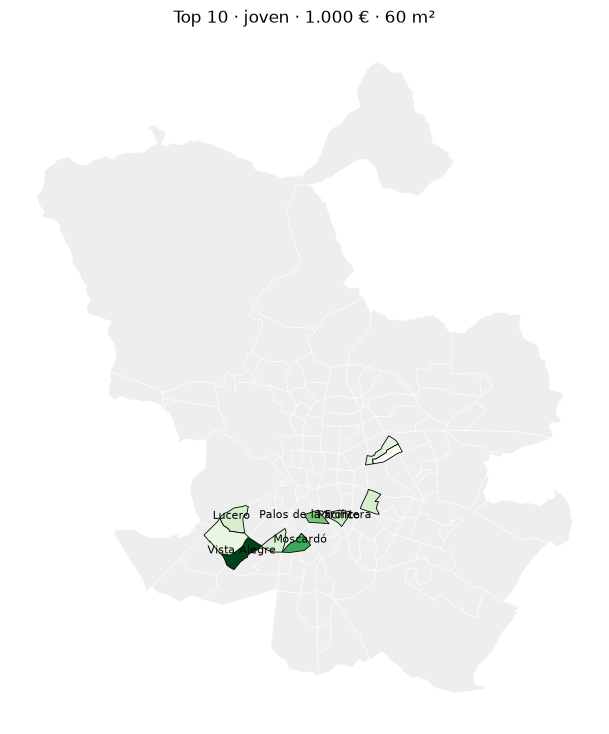

In [22]:
import matplotlib.pyplot as plt

def mapa_recomendacion(resultado, titulo):
    fig, ax = plt.subplots(figsize=(9, 9))
    b.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.4)
    resultado.plot(ax=ax, column="puntuacion", cmap="Greens", edgecolor="black", linewidth=0.6)
    for _, fila in resultado.head(5).iterrows():
        p = fila.geometry.representative_point()
        ax.annotate(fila["nombre"].split(" (")[0], (p.x, p.y), fontsize=8, ha="center")
    ax.set_axis_off()
    ax.set_title(titulo)

mapa_recomendacion(recomendar(1000, 60, PERFILES["joven"]), "Top 10 · joven · 1.000 € · 60 m²")

In [23]:
b.to_parquet(PROCESSED / "barrios_indices.parquet")